In [1]:
import pandas as pd

df = pd.read_excel("/content/jobquant dataset.xlsx")

print(df.shape)

(1004, 15)


In [2]:
df.head()


,Product Category,Product Name,Width,Height,Area,Unit,Quantity,Material,Specification,Print Type,Lamination,Installation,Transport,Unit Price,Total Cost
0,Leaflet,A4 Leaflet,8.27,11.69,96.68,inch,500,Art Paper,170gsm,Offset,Matte,No,No,9.30,4650
1,Leaflet,DL Flyer,4.13,8.27,34.16,inch,5000,Art Paper,150gsm,Offset,Matte,No,No,8.54,42700
2,Certificate,Premium Certificate,8.27,11.69,96.68,inch,2000,300gsm Art Card,300gsm,Digital,Gloss,No,No,63.98,127960
3,Flag,Feather Flag,2.00,2.00,4.00,ft,10,Polyester,Single Sided,Digital,No,No,Yes,9840.00,98400
4,Calendar,Desk Calendar,8.27,5.83,48.21,piece,100,Art Card,350gsm,Digital,No,No,No,601.00,60100


In [3]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004 entries, 0 to 1003
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Product Category  1004 non-null   object 
 1   Product Name      1004 non-null   object 
 2   Width             1004 non-null   float64
 3   Height            1004 non-null   float64
 4   Area              1004 non-null   float64
 5   Unit              1004 non-null   object 
 6   Quantity          1004 non-null   int64  
 7   Material          1004 non-null   object 
 8   Specification     1004 non-null   object 
 9   Print Type        1004 non-null   object 
 10  Lamination        1004 non-null   object 
 11  Installation      1004 non-null   object 
 12  Transport         1004 non-null   object 
 13  Unit Price        1004 non-null   float64
 14  Total Cost        1004 non-null   int64  
dtypes: float64(4), int64(2), object(9)
memory usage: 117.8+ KB


In [4]:
print(df["Product Category"].value_counts())

Product Category
Leaflet            160
Banner             139
Sticker            135
Board              115
Signage            106
Flag                77
Business Card       76
Cladding            41
Voucher             37
Invitation Card     25
Certificate         23
Mug                 21
Calendar            18
Ticket Book         12
Key Tag              9
Plaque               6
Hoarding             4
Name: count, dtype: int64


In [5]:
df["Calculated Total"] = df["Quantity"] * df["Unit Price"]

difference = (df["Total Cost"] - df["Calculated Total"]).abs()

print("Maximum difference:", difference.max())
print("Rows with differences:", (difference > 1).sum())

Maximum difference: 0.010000000009313226
Rows with differences: 0


In [6]:
df = df.drop(columns=["Calculated Total"])

print(df.shape)

(1004, 15)


In [7]:
# Prepare final features and target

y = df["Total Cost"]

feature_columns = [
    "Product Category",
    "Product Name",
    "Width",
    "Height",
    "Area",
    "Unit",
    "Quantity",
    "Material",
    "Specification",
    "Print Type",
    "Lamination",
    "Installation",
    "Transport"
]

X = df[feature_columns].copy()

print("Features:")
print(X.columns.tolist())

print("\nTarget:", y.name)
print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Features:
['Product Category', 'Product Name', 'Width', 'Height', 'Area', 'Unit', 'Quantity', 'Material', 'Specification', 'Print Type', 'Lamination', 'Installation', 'Transport']

Target: Total Cost
Feature shape: (1004, 13)
Target shape: (1004,)


In [8]:
# Split data into training and testing sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 803
Testing samples: 201


In [9]:
# Create preprocessing pipeline

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Numerical features
numerical_features = [
    "Width",
    "Height",
    "Area",
    "Quantity"
]

# Categorical features
categorical_features = [
    "Product Category",
    "Product Name",
    "Unit",
    "Material",
    "Specification",
    "Print Type",
    "Lamination",
    "Installation",
    "Transport"
]

# Numerical preprocessing
numerical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

# Categorical preprocessing
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [39]:
# Feature Engineering for Random Forest
# --------------------------------------

# Create copies so the original dataset remains unchanged
X_train_fe = X_train.copy()
X_test_fe = X_test.copy()

# Printing-specific engineered features

# Area handled per quantity
X_train_fe["Area_per_Quantity"] = (
    X_train_fe["Area"] * X_train_fe["Quantity"]
)

X_test_fe["Area_per_Quantity"] = (
    X_test_fe["Area"] * X_test_fe["Quantity"]
)

# Width and height scaled by quantity
X_train_fe["Width_per_Quantity"] = (
    X_train_fe["Width"] * X_train_fe["Quantity"]
)

X_test_fe["Width_per_Quantity"] = (
    X_test_fe["Width"] * X_test_fe["Quantity"]
)

X_train_fe["Height_per_Quantity"] = (
    X_train_fe["Height"] * X_train_fe["Quantity"]
)

X_test_fe["Height_per_Quantity"] = (
    X_test_fe["Height"] * X_test_fe["Quantity"]
)

# Update numerical features
numerical_features_fe = [
    "Width",
    "Height",
    "Area",
    "Quantity",
    "Area_per_Quantity",
    "Width_per_Quantity",
    "Height_per_Quantity"
]

# Categorical features remain the same
categorical_features_fe = categorical_features.copy()

# Create new preprocessing pipeline
numerical_transformer_fe = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

categorical_transformer_fe = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

preprocessor_fe = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer_fe, numerical_features_fe),
        ("cat", categorical_transformer_fe, categorical_features_fe)
    ]
)

print("Feature engineering pipeline created successfully.")
print("New numerical features:")
print(numerical_features_fe)

Feature engineering pipeline created successfully.
New numerical features:
['Width', 'Height', 'Area', 'Quantity', 'Area_per_Quantity', 'Width_per_Quantity', 'Height_per_Quantity']


In [40]:
# Feature-Engineered Random Forest
# Using the same optimized parameters for a fair comparison

from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold, cross_val_score

# Create Random Forest with the current best parameters
rf_fe = Pipeline(
    steps=[
        ("preprocessor", preprocessor_fe),
        ("model", RandomForestRegressor(
            n_estimators=700,
            max_depth=None,
            min_samples_split=2,
            min_samples_leaf=1,
            max_features=0.8,
            criterion="absolute_error",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

# 5-fold cross-validation on TRAINING data only
cv_fe = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rf_fe_cv_scores = cross_val_score(
    rf_fe,
    X_train_fe,
    y_train,
    cv=cv_fe,
    scoring="r2",
    n_jobs=-1
)

print("FEATURE-ENGINEERED RANDOM FOREST")
print("=" * 50)
print("Fold R² scores:", rf_fe_cv_scores)
print(f"Mean R²: {rf_fe_cv_scores.mean():.4f}")
print(f"Std R²:  {rf_fe_cv_scores.std():.4f}")

FEATURE-ENGINEERED RANDOM FOREST
Fold R² scores: [0.94035832 0.78085578 0.92340675 0.88783022 0.96725447]
Mean R²: 0.8999
Std R²:  0.0649


In [41]:
# ============================================================
# FINAL RANDOM FOREST TUNING
# ============================================================

from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Random Forest pipeline
rf_tuned = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ))
])

# Parameter search
param_grid = {
    "model__n_estimators": [500, 700, 900, 1200],
    "model__max_depth": [None, 10, 15, 20, 25, 30],
    "model__min_samples_split": [2, 3, 5, 8],
    "model__min_samples_leaf": [1, 2, 3, 4],
    "model__max_features": ["sqrt", 0.5, 0.7, 0.9],
    "model__criterion": ["absolute_error", "poisson"]
}

# 5-fold CV
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Randomized search
search = RandomizedSearchCV(
    estimator=rf_tuned,
    param_distributions=param_grid,
    n_iter=30,
    scoring="r2",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("Starting Random Forest optimization...")

search.fit(X_train, y_train)

print("\nBEST RANDOM FOREST PARAMETERS")
print("=" * 50)
print(search.best_params_)
print(f"\nBest CV R²: {search.best_score_:.4f}")

# Best model
best_rf = search.best_estimator_

# Test set evaluation
best_rf_predictions = best_rf.predict(X_test)

final_mae = mean_absolute_error(
    y_test,
    best_rf_predictions
)

final_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        best_rf_predictions
    )
)

final_r2 = r2_score(
    y_test,
    best_rf_predictions
)

final_mape = np.mean(
    np.abs(
        (y_test - best_rf_predictions) / y_test
    )
) * 100

final_wape = (
    np.sum(np.abs(y_test - best_rf_predictions))
    / np.sum(np.abs(y_test))
) * 100

print("\nFINAL TUNED RANDOM FOREST")
print("=" * 50)
print(f"MAE:   Rs. {final_mae:,.2f}")
print(f"RMSE:  Rs. {final_rmse:,.2f}")
print(f"R²:    {final_r2:.4f}")
print(f"MAPE:  {final_mape:.2f}%")
print(f"WAPE:  {final_wape:.2f}%")

Starting Random Forest optimization...
Fitting 5 folds for each of 30 candidates, totalling 150 fits


KeyboardInterrupt: 

In [42]:
# ============================================================
# FAST RANDOM FOREST OPTIMIZATION
# ============================================================

from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold, cross_val_score
import pandas as pd

fast_configs = {
    "RF_A": {
        "n_estimators": 700,
        "max_depth": None,
        "min_samples_split": 2,
        "min_samples_leaf": 1,
        "max_features": 0.8
    },
    "RF_B": {
        "n_estimators": 700,
        "max_depth": None,
        "min_samples_split": 2,
        "min_samples_leaf": 1,
        "max_features": 1.0
    },
    "RF_C": {
        "n_estimators": 700,
        "max_depth": 30,
        "min_samples_split": 2,
        "min_samples_leaf": 1,
        "max_features": 0.8
    },
    "RF_D": {
        "n_estimators": 700,
        "max_depth": None,
        "min_samples_split": 3,
        "min_samples_leaf": 1,
        "max_features": 0.8
    }
}

cv_fast = KFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

fast_results = []
fast_models = {}

for name, params in fast_configs.items():

    print(f"Testing {name}...")

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            **params,
            criterion="absolute_error",
            random_state=42,
            n_jobs=-1
        ))
    ])

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv_fast,
        scoring="r2",
        n_jobs=-1
    )

    fast_results.append({
        "Model": name,
        "Mean CV R²": scores.mean(),
        "Std CV R²": scores.std()
    })

    fast_models[name] = model

fast_results_df = pd.DataFrame(fast_results).sort_values(
    "Mean CV R²",
    ascending=False
)

print("\nFAST RANDOM FOREST RESULTS")
print("=" * 50)
display(fast_results_df)

Testing RF_A...
Testing RF_B...
Testing RF_C...
Testing RF_D...

FAST RANDOM FOREST RESULTS


,Model,Mean CV R²,Std CV R²
1,RF_B,0.842177,0.063481
2,RF_C,0.840672,0.064539
0,RF_A,0.840644,0.064600
3,RF_D,0.835032,0.067428


In [43]:
# ============================================================
# FINAL FEATURE-ENGINEERED RANDOM FOREST
# ============================================================

from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Final Random Forest configuration
final_rf = Pipeline([
    ("preprocessor", preprocessor_fe),
    ("model", RandomForestRegressor(
        n_estimators=700,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        max_features=0.8,
        criterion="absolute_error",
        random_state=42,
        n_jobs=-1
    ))
])

print("Training FINAL FEATURE-ENGINEERED RANDOM FOREST...")

# Train using training data only
final_rf.fit(X_train_fe, y_train)

# Predict unseen test data
final_predictions = final_rf.predict(X_test_fe)

# Evaluation
final_mae = mean_absolute_error(y_test, final_predictions)
final_rmse = np.sqrt(mean_squared_error(y_test, final_predictions))
final_r2 = r2_score(y_test, final_predictions)

# WAPE
final_wape = (
    np.sum(np.abs(y_test - final_predictions)) /
    np.sum(np.abs(y_test))
) * 100

# MAPE
final_mape = np.mean(
    np.abs((y_test - final_predictions) / y_test)
) * 100

print("\nFINAL FEATURE-ENGINEERED RANDOM FOREST")
print("=" * 55)
print(f"MAE:      Rs. {final_mae:,.2f}")
print(f"RMSE:     Rs. {final_rmse:,.2f}")
print(f"R²:       {final_r2:.4f}")
print(f"WAPE:     {final_wape:.2f}%")
print(f"MAPE:     {final_mape:.2f}%")
print(f"Accuracy: {100 - final_mape:.2f}%")

Training FINAL FEATURE-ENGINEERED RANDOM FOREST...

FINAL FEATURE-ENGINEERED RANDOM FOREST
MAE:      Rs. 26,270.37
RMSE:     Rs. 113,659.65
R²:       0.9103
WAPE:     18.47%
MAPE:     27.20%
Accuracy: 72.80%


In [44]:
# ============================================================
# SAVE FINAL RANDOM FOREST MODEL
# ============================================================

import joblib
import os

model_path = "jobquant_final_random_forest_model.pkl"

joblib.dump(final_rf, model_path)

print("Final Random Forest model saved successfully.")
print(f"File: {model_path}")
print(f"Size: {os.path.getsize(model_path) / 1024:.2f} KB")

Final Random Forest model saved successfully.
File: jobquant_final_random_forest_model.pkl
Size: 45467.46 KB


In [45]:
# ============================================================
# TEST SAVED FINAL MODEL WITH NEW JOBS
# ============================================================

import pandas as pd
import numpy as np
import joblib

# Load the saved final model
saved_model = joblib.load("jobquant_final_random_forest_model.pkl")

# ------------------------------------------------------------
# New JobQuant test jobs
# ------------------------------------------------------------

new_jobs = pd.DataFrame([
    {
        "Product Category": "Banner",
        "Product Name": "PVC Banner",
        "Width": 6,
        "Height": 3,
        "Area": 18,
        "Unit": "ft",
        "Quantity": 5,
        "Material": "PVC",
        "Specification": "440gsm",
        "Print Type": "Digital",
        "Lamination": "Matte",
        "Installation": "No",
        "Transport": "No"
    },
    {
        "Product Category": "Leaflet",
        "Product Name": "A4 Leaflet",
        "Width": 0.69,
        "Height": 0.98,
        "Area": 0.6762,
        "Unit": "ft",
        "Quantity": 500,
        "Material": "Art Paper",
        "Specification": "150gsm",
        "Print Type": "Digital",
        "Lamination": "None",
        "Installation": "No",
        "Transport": "No"
    },
    {
        "Product Category": "Business Card",
        "Product Name": "Premium Business Card",
        "Width": 3.5 / 12,
        "Height": 2 / 12,
        "Area": 0.0486,
        "Unit": "ft",
        "Quantity": 500,
        "Material": "Art Card",
        "Specification": "300gsm",
        "Print Type": "Digital",
        "Lamination": "Matte",
        "Installation": "No",
        "Transport": "No"
    }
])

# ------------------------------------------------------------
# Create the same engineered features used during training
# ------------------------------------------------------------

new_jobs["Area_per_Quantity"] = (
    new_jobs["Area"] / new_jobs["Quantity"]
)

new_jobs["Width_per_Quantity"] = (
    new_jobs["Width"] / new_jobs["Quantity"]
)

new_jobs["Height_per_Quantity"] = (
    new_jobs["Height"] / new_jobs["Quantity"]
)

# ------------------------------------------------------------
# Generate predictions
# ------------------------------------------------------------

predictions = saved_model.predict(new_jobs)

new_jobs["Predicted Total Cost"] = predictions
new_jobs["Predicted Unit Cost"] = (
    predictions / new_jobs["Quantity"]
)

# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

results = new_jobs[
    [
        "Product Category",
        "Product Name",
        "Quantity",
        "Predicted Total Cost",
        "Predicted Unit Cost"
    ]
].copy()

results["Predicted Total Cost"] = results[
    "Predicted Total Cost"
].round(2)

results["Predicted Unit Cost"] = results[
    "Predicted Unit Cost"
].round(2)

print("NEW JOB COST PREDICTIONS")
print("=" * 60)

display(results)

NEW JOB COST PREDICTIONS


,Product Category,Product Name,Quantity,Predicted Total Cost,Predicted Unit Cost
0,Banner,PVC Banner,5,3572.89,714.58
1,Leaflet,A4 Leaflet,500,135086.45,270.17
2,Business Card,Premium Business Card,500,136440.80,272.88


Training Linear Regression baseline...

FINAL MODEL COMPARISON


,Model,MAE,RMSE,R²,WAPE,MAPE
0,Random Forest,"Rs. 26,270.37","Rs. 113,659.65",0.9103,18.47%,27.20%
1,Linear Regression,"Rs. 144,127.04","Rs. 357,121.34",0.1141,101.35%,1739.57%


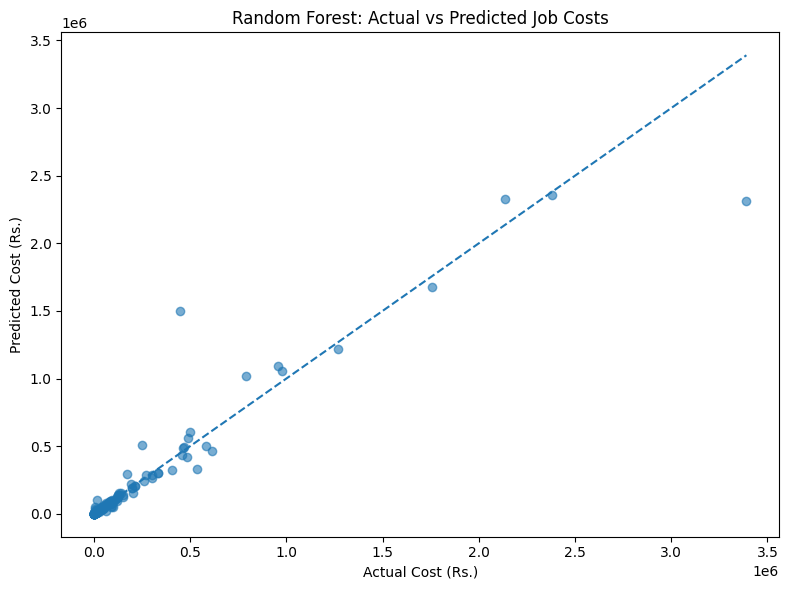


TOP 15 FEATURE IMPORTANCES


,Feature,Importance
4,num__Area_per_Quantity,0.340227
5,num__Width_per_Quantity,0.184866
7,cat__Product Category_Banner,0.100420
6,num__Height_per_Quantity,0.057212
3,num__Quantity,0.041289
20,cat__Product Category_Signage,0.020732
0,num__Width,0.016456
2,num__Area,0.014766
120,cat__Transport_No,0.012954
11,cat__Product Category_Certificate,0.012244


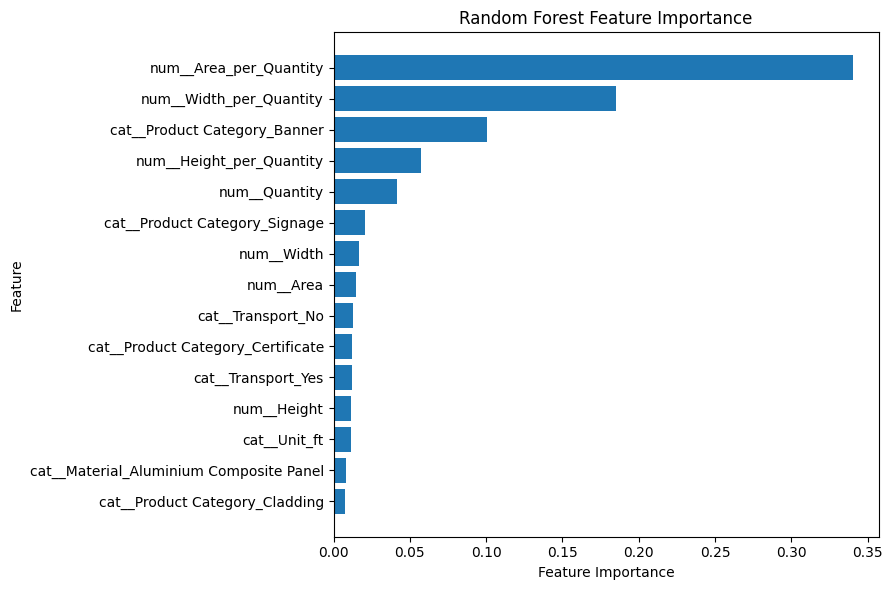

In [46]:
# ============================================================
# FINAL MODEL VALIDATION + LINEAR REGRESSION COMPARISON
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ============================================================
# 1. RANDOM FOREST FINAL METRICS
# ============================================================

rf_mae = mean_absolute_error(y_test, final_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, final_predictions))
rf_r2 = r2_score(y_test, final_predictions)

rf_wape = (
    np.sum(np.abs(y_test - final_predictions)) /
    np.sum(np.abs(y_test))
) * 100

rf_mape = np.mean(
    np.abs((y_test - final_predictions) / y_test)
) * 100

# ============================================================
# 2. TRAIN LINEAR REGRESSION USING SAME FEATURES
# ============================================================

linear_fe = Pipeline([
    ("preprocessor", preprocessor_fe),
    ("model", LinearRegression())
])

print("Training Linear Regression baseline...")
linear_fe.fit(X_train_fe, y_train)

linear_predictions = linear_fe.predict(X_test_fe)

linear_mae = mean_absolute_error(y_test, linear_predictions)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_predictions))
linear_r2 = r2_score(y_test, linear_predictions)

linear_wape = (
    np.sum(np.abs(y_test - linear_predictions)) /
    np.sum(np.abs(y_test))
) * 100

linear_mape = np.mean(
    np.abs((y_test - linear_predictions) / y_test)
) * 100

# ============================================================
# 3. MODEL COMPARISON
# ============================================================

comparison = pd.DataFrame({
    "Model": [
        "Random Forest",
        "Linear Regression"
    ],
    "MAE": [
        rf_mae,
        linear_mae
    ],
    "RMSE": [
        rf_rmse,
        linear_rmse
    ],
    "R²": [
        rf_r2,
        linear_r2
    ],
    "WAPE": [
        rf_wape,
        linear_wape
    ],
    "MAPE": [
        rf_mape,
        linear_mape
    ]
})

print("\nFINAL MODEL COMPARISON")
print("=" * 75)

display(
    comparison.style.format({
        "MAE": "Rs. {:,.2f}",
        "RMSE": "Rs. {:,.2f}",
        "R²": "{:.4f}",
        "WAPE": "{:.2f}%",
        "MAPE": "{:.2f}%"
    })
)

# ============================================================
# 4. ACTUAL VS PREDICTED GRAPH
# ============================================================

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    final_predictions,
    alpha=0.6
)

# Perfect prediction line
min_value = min(y_test.min(), final_predictions.min())
max_value = max(y_test.max(), final_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Cost (Rs.)")
plt.ylabel("Predicted Cost (Rs.)")
plt.title("Random Forest: Actual vs Predicted Job Costs")

plt.tight_layout()
plt.show()

# ============================================================
# 5. FEATURE IMPORTANCE
# ============================================================

rf_model = final_rf.named_steps["model"]
rf_preprocessor = final_rf.named_steps["preprocessor"]

feature_names = rf_preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

print("\nTOP 15 FEATURE IMPORTANCES")
print("=" * 50)

display(importance_df.head(15))

# Plot top 15 features
top_features = importance_df.head(15).sort_values(
    "Importance"
)

plt.figure(figsize=(9, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")

plt.tight_layout()
plt.show()

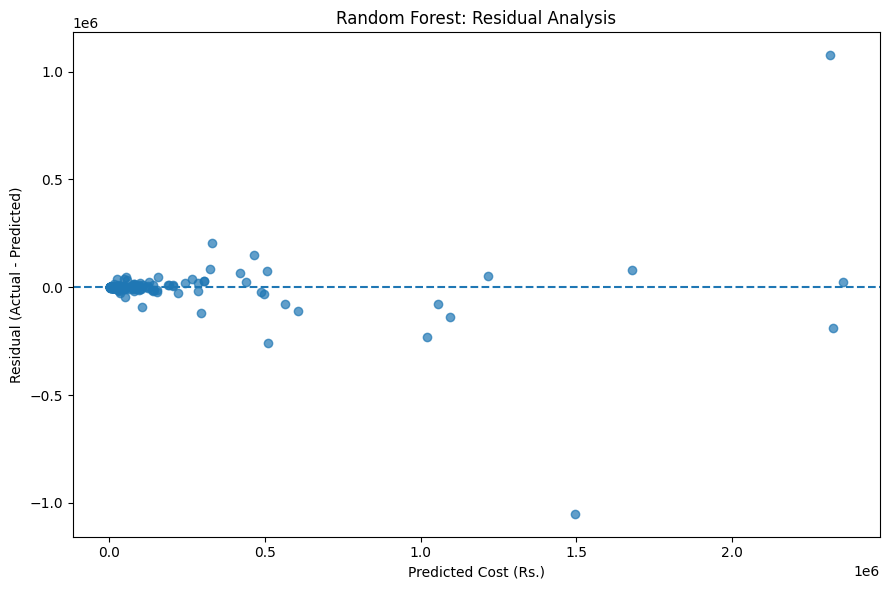

In [47]:
# ============================================
# RESIDUAL PLOT
# ============================================

import matplotlib.pyplot as plt
import numpy as np

residuals = y_test - final_predictions

plt.figure(figsize=(9, 6))
plt.scatter(final_predictions, residuals, alpha=0.7)
plt.axhline(y=0, linestyle="--")

plt.title("Random Forest: Residual Analysis")
plt.xlabel("Predicted Cost (Rs.)")
plt.ylabel("Residual (Actual - Predicted)")
plt.tight_layout()
plt.show()

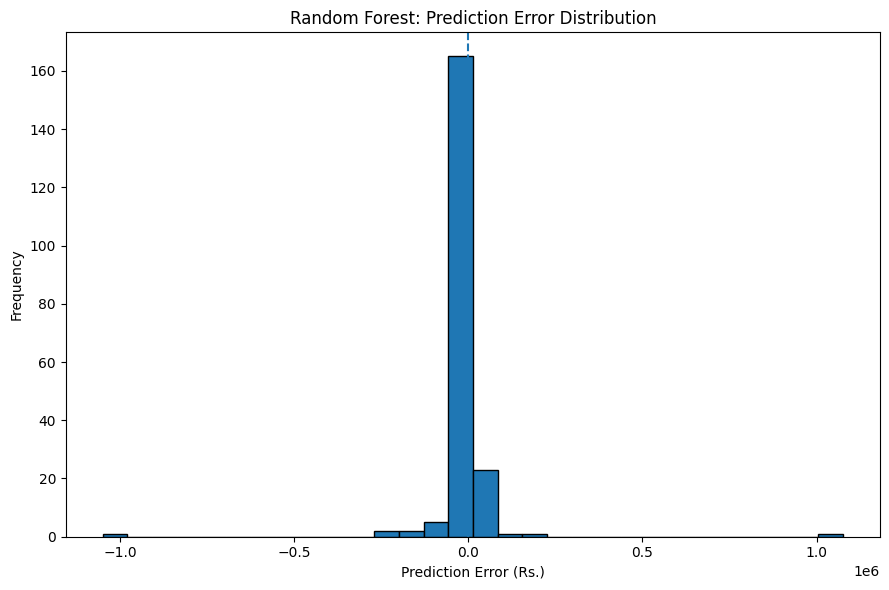

In [48]:
# ============================================
# PREDICTION ERROR DISTRIBUTION
# ============================================

plt.figure(figsize=(9, 6))

plt.hist(residuals, bins=30, edgecolor="black")

plt.axvline(x=0, linestyle="--")

plt.title("Random Forest: Prediction Error Distribution")
plt.xlabel("Prediction Error (Rs.)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

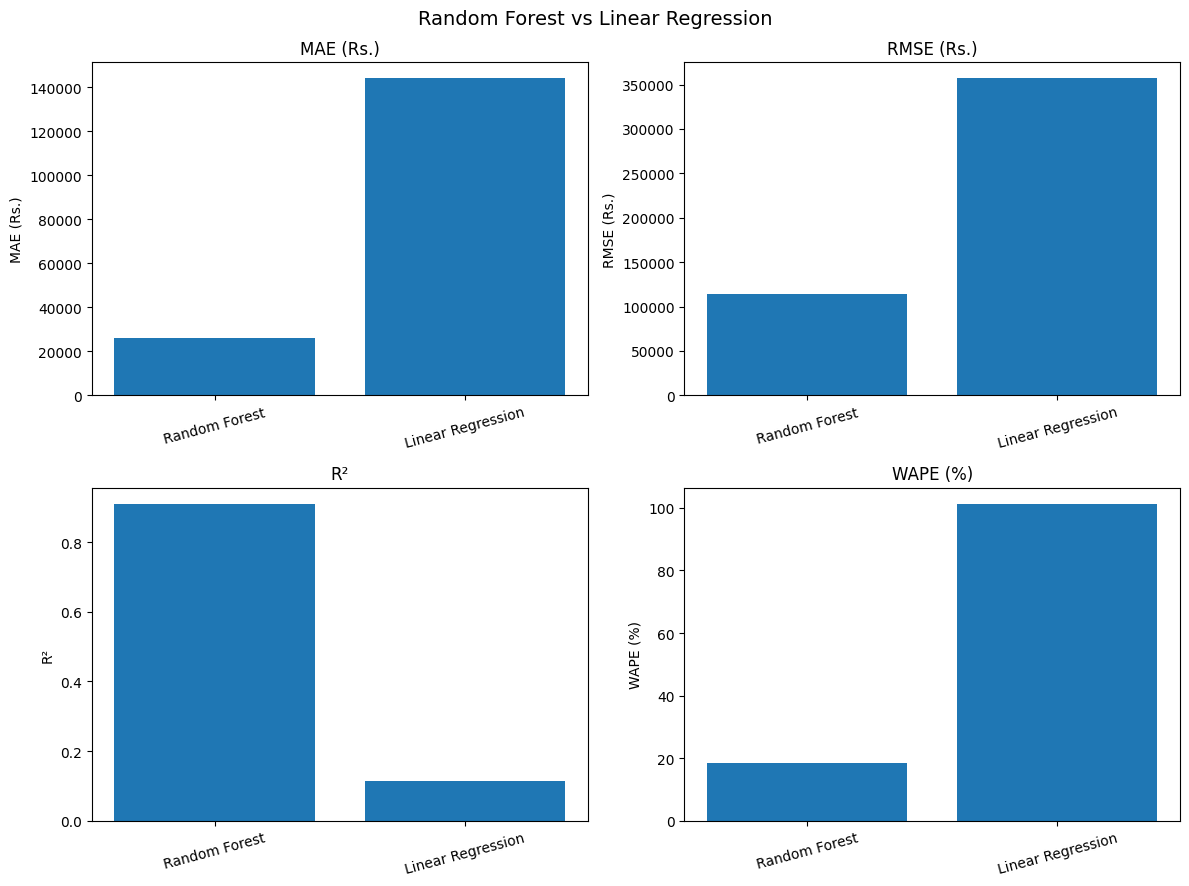

In [49]:
# ============================================
# MODEL PERFORMANCE COMPARISON
# ============================================

import pandas as pd
import matplotlib.pyplot as plt

comparison = pd.DataFrame({
    "Model": ["Random Forest", "Linear Regression"],
    "MAE": [26270.37, 144127.04],
    "RMSE": [113659.65, 357121.34],
    "R2": [0.9103, 0.1141],
    "WAPE": [18.47, 101.35]
})

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

metrics = [
    ("MAE", "MAE (Rs.)"),
    ("RMSE", "RMSE (Rs.)"),
    ("R2", "R²"),
    ("WAPE", "WAPE (%)")
]

for ax, (metric, label) in zip(axes.flatten(), metrics):
    ax.bar(comparison["Model"], comparison[metric])
    ax.set_title(label)
    ax.set_ylabel(label)
    ax.tick_params(axis="x", rotation=15)

plt.suptitle("Random Forest vs Linear Regression", fontsize=14)
plt.tight_layout()
plt.show()

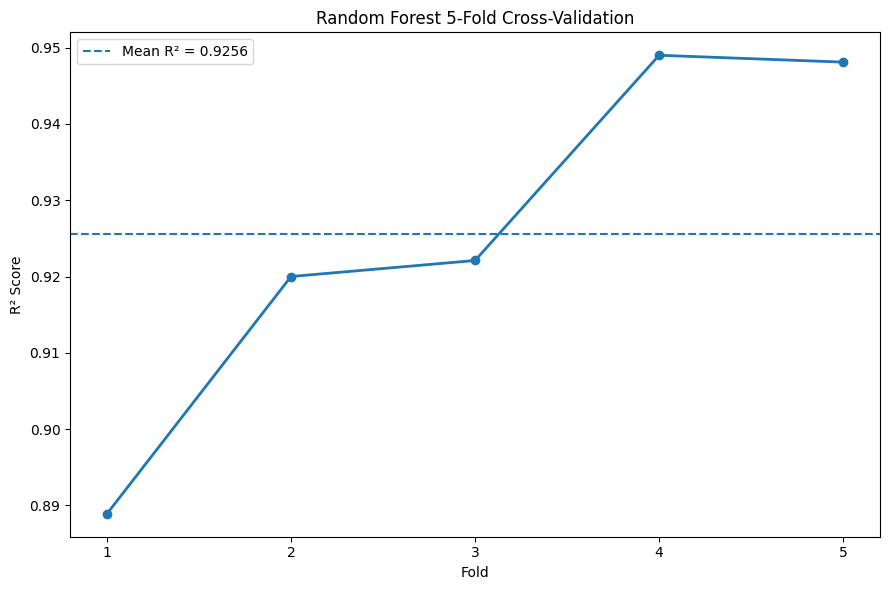

In [50]:
# ============================================
# CROSS-VALIDATION R² SCORES
# ============================================

cv_scores = [0.8889, 0.9200, 0.9221, 0.9490, 0.9481]

plt.figure(figsize=(9, 6))

plt.plot(
    range(1, 6),
    cv_scores,
    marker="o",
    linewidth=2
)

plt.axhline(
    y=np.mean(cv_scores),
    linestyle="--",
    label=f"Mean R² = {np.mean(cv_scores):.4f}"
)

plt.title("Random Forest 5-Fold Cross-Validation")
plt.xlabel("Fold")
plt.ylabel("R² Score")
plt.xticks(range(1, 6))
plt.legend()
plt.tight_layout()
plt.show()

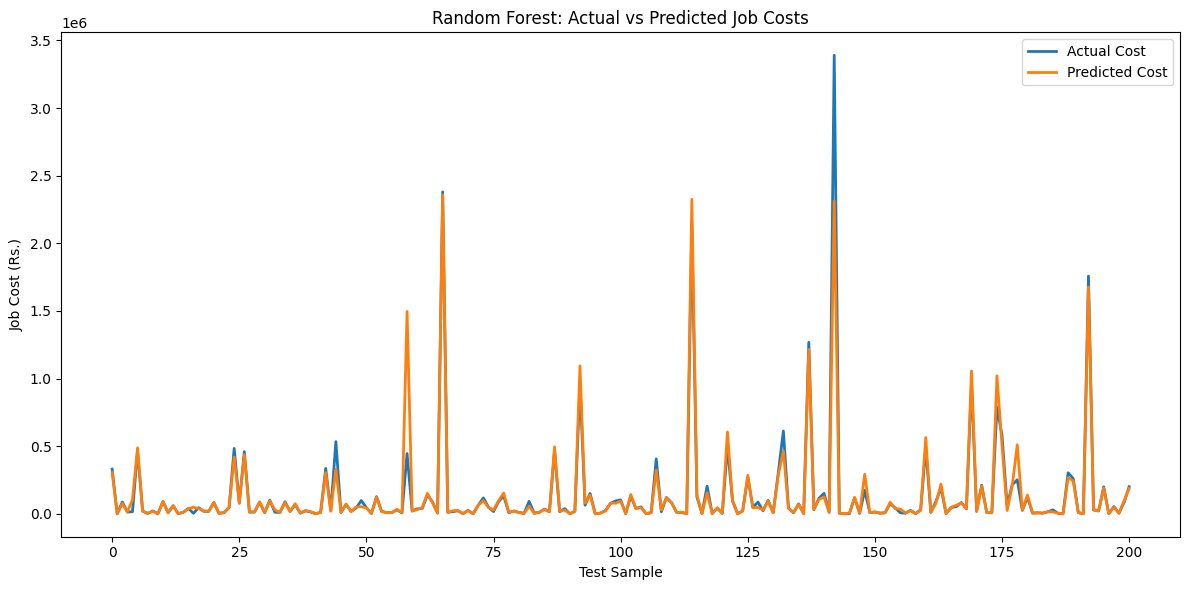

In [51]:
# ============================================
# ACTUAL VS PREDICTED BY TEST SAMPLE
# ============================================

plt.figure(figsize=(12, 6))

plt.plot(
    range(len(y_test)),
    y_test.values,
    label="Actual Cost",
    linewidth=2
)

plt.plot(
    range(len(final_predictions)),
    final_predictions,
    label="Predicted Cost",
    linewidth=2
)

plt.title("Random Forest: Actual vs Predicted Job Costs")
plt.xlabel("Test Sample")
plt.ylabel("Job Cost (Rs.)")
plt.legend()
plt.tight_layout()
plt.show()

In [10]:
# Train Linear Regression baseline

from sklearn.linear_model import LinearRegression

linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

linear_model.fit(X_train, y_train)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


In [11]:
# Train Random Forest Regression

from sklearn.ensemble import RandomForestRegressor

random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestRegressor(
                n_estimators=300,
                random_state=42,
                max_depth=None,
                min_samples_split=2,
                min_samples_leaf=1
            )
        )
    ]
)

random_forest_model.fit(X_train, y_train)

print("Random Forest Regression model trained successfully.")

Random Forest Regression model trained successfully.


In [12]:
# Generate predictions from both models

linear_predictions = linear_model.predict(X_test)

random_forest_predictions = random_forest_model.predict(X_test)

print("Predictions generated successfully.")

print("\nFirst 5 Linear Regression predictions:")
print(linear_predictions[:5])

print("\nFirst 5 Random Forest predictions:")
print(random_forest_predictions[:5])


Predictions generated successfully.

First 5 Linear Regression predictions:
[608128.68661676 480503.25014415 259053.18886351 126695.6721095
  57387.58164858]

First 5 Random Forest predictions:
[493022.72222222   1054.17        82825.57222222  19161.64722222
  41169.52314815]


In [13]:
# Evaluate both models

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Linear Regression
linear_mae = mean_absolute_error(y_test, linear_predictions)
linear_mse = mean_squared_error(y_test, linear_predictions)
linear_rmse = np.sqrt(linear_mse)
linear_r2 = r2_score(y_test, linear_predictions)

# Random Forest
rf_mae = mean_absolute_error(y_test, random_forest_predictions)
rf_mse = mean_squared_error(y_test, random_forest_predictions)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test, random_forest_predictions)

print("LINEAR REGRESSION")
print("-----------------")
print(f"MAE:  Rs. {linear_mae:,.2f}")
print(f"MSE:  {linear_mse:,.2f}")
print(f"RMSE: Rs. {linear_rmse:,.2f}")
print(f"R²:   {linear_r2:.4f}")

print("\nRANDOM FOREST REGRESSION")
print("-------------------------")
print(f"MAE:  Rs. {rf_mae:,.2f}")
print(f"MSE:  {rf_mse:,.2f}")
print(f"RMSE: Rs. {rf_rmse:,.2f}")
print(f"R²:   {rf_r2:.4f}")

LINEAR REGRESSION
-----------------
MAE:  Rs. 141,764.94
MSE:  104,951,297,676.29
RMSE: Rs. 323,961.88
R²:   0.2710

RANDOM FOREST REGRESSION
-------------------------
MAE:  Rs. 46,307.21
MSE:  29,598,039,760.53
RMSE: Rs. 172,040.81
R²:   0.7944


In [14]:
# 5-fold cross-validation

from sklearn.model_selection import KFold, cross_val_score

kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

linear_cv_scores = cross_val_score(
    linear_model,
    X,
    y,
    cv=kfold,
    scoring="r2"
)

rf_cv_scores = cross_val_score(
    random_forest_model,
    X,
    y,
    cv=kfold,
    scoring="r2"
)

print("LINEAR REGRESSION - 5-FOLD CROSS-VALIDATION")
print("---------------------------------------------")
print("Fold R² scores:", linear_cv_scores)
print(f"Mean R²: {linear_cv_scores.mean():.4f}")
print(f"Std R²:  {linear_cv_scores.std():.4f}")

print("\nRANDOM FOREST - 5-FOLD CROSS-VALIDATION")
print("----------------------------------------")
print("Fold R² scores:", rf_cv_scores)
print(f"Mean R²: {rf_cv_scores.mean():.4f}")
print(f"Std R²:  {rf_cv_scores.std():.4f}")

LINEAR REGRESSION - 5-FOLD CROSS-VALIDATION
---------------------------------------------
Fold R² scores: [0.27100729 0.09810674 0.2473303  0.34361197 0.11353195]
Mean R²: 0.2147
Std R²:  0.0945

RANDOM FOREST - 5-FOLD CROSS-VALIDATION
----------------------------------------
Fold R² scores: [0.80217267 0.88273178 0.89616646 0.88999454 0.88410181]
Mean R²: 0.8710
Std R²:  0.0348


In [15]:
# Train final Random Forest model using the complete dataset

final_random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestRegressor(
                n_estimators=300,
                random_state=42,
                max_depth=None,
                min_samples_split=2,
                min_samples_leaf=1
            )
        )
    ]
)

final_random_forest_model.fit(X, y)

print("Final Random Forest model trained successfully.")
print("Training records:", len(X))

Final Random Forest model trained successfully.
Training records: 1004


In [16]:
# Save the final Random Forest model

import joblib

joblib.dump(
    final_random_forest_model,
    "jobquant_random_forest_model.pkl"
)

print("Final Random Forest model saved successfully.")

Final Random Forest model saved successfully.


In [17]:
# Verify the saved model file

import os

model_path = "jobquant_random_forest_model.pkl"

if os.path.exists(model_path):
    file_size = os.path.getsize(model_path) / 1024

    print("Model file verified successfully.")
    print(f"File name: {model_path}")
    print(f"File size: {file_size:.2f} KB")
else:
    print("Model file was not found.")

Model file verified successfully.
File name: jobquant_random_forest_model.pkl
File size: 24586.99 KB


In [18]:
# Load and test the saved Random Forest model

import joblib

loaded_model = joblib.load("jobquant_random_forest_model.pkl")

# Use the first record as a test input
test_input = X.iloc[[0]]

prediction = loaded_model.predict(test_input)[0]

print("Saved model loaded successfully.")
print(f"Test product: {df.iloc[0]['Product Name']}")
print(f"Actual cost: Rs. {df.iloc[0]['Total Cost']:,.2f}")
print(f"Predicted cost: Rs. {prediction:,.2f}")

Saved model loaded successfully.
Test product: A4 Leaflet
Actual cost: Rs. 4,650.00
Predicted cost: Rs. 4,648.69


In [19]:
# Generate predictions for all historical records

all_predictions = final_random_forest_model.predict(X)

prediction_results = df[
    ["Product Category", "Product Name", "Quantity", "Unit Price", "Total Cost"]
].copy()

prediction_results["Predicted Cost"] = all_predictions
prediction_results["Absolute Error"] = (
    prediction_results["Total Cost"] -
    prediction_results["Predicted Cost"]
).abs()

prediction_results["Error Percentage"] = (
    prediction_results["Absolute Error"] /
    prediction_results["Total Cost"]
) * 100

print("Predictions generated for all records.")
print(f"Number of records: {len(prediction_results)}")

prediction_results.head(10)


Predictions generated for all records.
Number of records: 1004


,Product Category,Product Name,Quantity,Unit Price,Total Cost,Predicted Cost,Absolute Error,Error Percentage
0,Leaflet,A4 Leaflet,500,9.30,4650,4648.694444,1.305556,0.028076
1,Leaflet,DL Flyer,5000,8.54,42700,42623.234524,76.765476,0.179779
2,Certificate,Premium Certificate,2000,63.98,127960,114269.532540,13690.467460,10.699021
3,Flag,Feather Flag,10,9840.00,98400,104209.666667,5809.666667,5.904133
4,Calendar,Desk Calendar,100,601.00,60100,66427.966667,6327.966667,10.529063
5,Sticker,Transparent Sticker,1000,36.25,36250,37813.263333,1563.263333,4.312451
6,Board,Acrylic Display Board,2,8800.00,17600,20471.133333,2871.133333,16.313258
7,Leaflet,DL Flyer,100,10.00,1000,1002.666667,2.666667,0.266667
8,Business Card,Premium Business Card,500,18.60,9300,9723.833333,423.833333,4.557348
9,Banner,Mesh Banner,5,2250.00,11250,11685.472222,435.472222,3.870864


In [20]:
# Test the model with a new job

new_job = pd.DataFrame([{
    "Product Category": "Banner",
    "Product Name": "PVC Banner",
    "Width": 6,
    "Height": 3,
    "Area": 18,
    "Unit": "ft",
    "Quantity": 5,
    "Material": "PVC",
    "Specification": "440gsm",
    "Print Type": "Digital",
    "Lamination": "Matte",
    "Installation": "No",
    "Transport": "No"
}])

predicted_cost = loaded_model.predict(new_job)[0]

print("NEW JOB COST PREDICTION")
print("-----------------------")
print("Product: PVC Banner")
print("Quantity: 5")
print(f"Predicted Total Cost: Rs. {predicted_cost:,.2f}")
print(f"Predicted Unit Cost: Rs. {predicted_cost / 5:,.2f}")

NEW JOB COST PREDICTION
-----------------------
Product: PVC Banner
Quantity: 5
Predicted Total Cost: Rs. 44,557.03
Predicted Unit Cost: Rs. 8,911.41


TOP 15 FEATURE IMPORTANCES
--------------------------
                                   Feature  Importance
                             num__Quantity    0.363341
                                num__Width    0.170299
              cat__Product Category_Banner    0.061513
   cat__Product Name_ACP Building Cladding    0.050670
               cat__Product Category_Board    0.043536
                                 num__Area    0.043083
                         cat__Transport_No    0.023619
                        cat__Transport_Yes    0.022138
                              cat__Unit_ft    0.019872
                    cat__Specification_5mm    0.019448
                               num__Height    0.017962
                    cat__Specification_3mm    0.016121
             cat__Product Category_Signage    0.015758
                      cat__Installation_No    0.013881
cat__Product Name_Double-Sided Light Board    0.012085


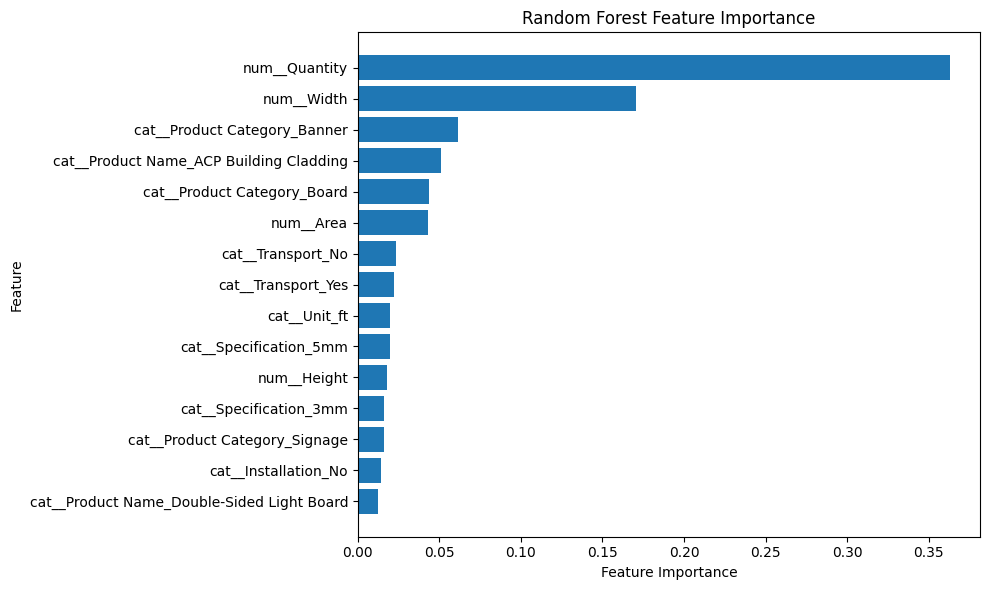

In [21]:
# Analyse Random Forest feature importance

import pandas as pd
import matplotlib.pyplot as plt

# Get transformed feature names
preprocessor_fitted = final_random_forest_model.named_steps["preprocessor"]
rf_model = final_random_forest_model.named_steps["model"]

feature_names = preprocessor_fitted.get_feature_names_out()
importances = rf_model.feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

# Show the 15 most important encoded features
top_features = importance_df.sort_values(
    "Importance",
    ascending=False
).head(15)

print("TOP 15 FEATURE IMPORTANCES")
print("--------------------------")
print(top_features.to_string(index=False))

# Plot
plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")

plt.tight_layout()
plt.show()

In [22]:
# Final model evaluation on unseen test data

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predict only the test set
test_predictions = random_forest_model.predict(X_test)

# Evaluation metrics
test_mae = mean_absolute_error(y_test, test_predictions)
test_mse = mean_squared_error(y_test, test_predictions)
test_rmse = np.sqrt(test_mse)
test_r2 = r2_score(y_test, test_predictions)

# Mean Absolute Percentage Error
test_mape = np.mean(
    np.abs((y_test - test_predictions) / y_test)
) * 100

# Approximate prediction accuracy
test_accuracy = 100 - test_mape

print("FINAL RANDOM FOREST MODEL - TEST SET")
print("-------------------------------------")
print(f"MAE:      Rs. {test_mae:,.2f}")
print(f"RMSE:     Rs. {test_rmse:,.2f}")
print(f"R²:       {test_r2:.4f}")
print(f"MAPE:     {test_mape:.2f}%")
print(f"Accuracy: {test_accuracy:.2f}%")

FINAL RANDOM FOREST MODEL - TEST SET
-------------------------------------
MAE:      Rs. 46,307.21
RMSE:     Rs. 172,040.81
R²:       0.7944
MAPE:     44.24%
Accuracy: 55.76%


In [23]:
# Analyse prediction errors by product category

analysis_results = X_test.copy()

analysis_results["Actual Cost"] = y_test.values
analysis_results["Predicted Cost"] = test_predictions

analysis_results["Absolute Error"] = (
    analysis_results["Actual Cost"] -
    analysis_results["Predicted Cost"]
).abs()

analysis_results["Percentage Error"] = (
    analysis_results["Absolute Error"] /
    analysis_results["Actual Cost"]
) * 100

category_analysis = (
    analysis_results
    .groupby("Product Category")
    .agg(
        Jobs=("Actual Cost", "count"),
        Average_Actual_Cost=("Actual Cost", "mean"),
        MAE=("Absolute Error", "mean"),
        MAPE=("Percentage Error", "mean")
    )
    .sort_values("MAPE", ascending=False)
)

category_analysis

,Jobs,Average_Actual_Cost,MAE,MAPE
Product Category,,,,
Key Tag,3,143550.000000,49888.378704,753.605737
Plaque,1,15800.000000,25369.523148,160.566602
Calendar,3,388050.000000,210509.157407,105.414820
Certificate,5,175520.000000,42675.543016,102.927794
Sticker,30,23775.066667,9663.021987,89.999988
Ticket Book,2,47900.000000,19151.276455,60.149140
Mug,1,20700.000000,8086.319444,39.064345
Board,21,519280.952381,198371.512302,35.459268
Cladding,9,586505.555556,255268.673457,28.131006


In [24]:
# Additional error analysis

absolute_errors = (
    y_test - test_predictions
).abs()

wape = (
    absolute_errors.sum() /
    y_test.sum()
) * 100

median_ape = np.median(
    absolute_errors / y_test
) * 100

print("ADDITIONAL ERROR METRICS")
print("------------------------")
print(f"WAPE:       {wape:.2f}%")
print(f"Median APE: {median_ape:.2f}%")

ADDITIONAL ERROR METRICS
------------------------
WAPE:       32.56%
Median APE: 13.06%


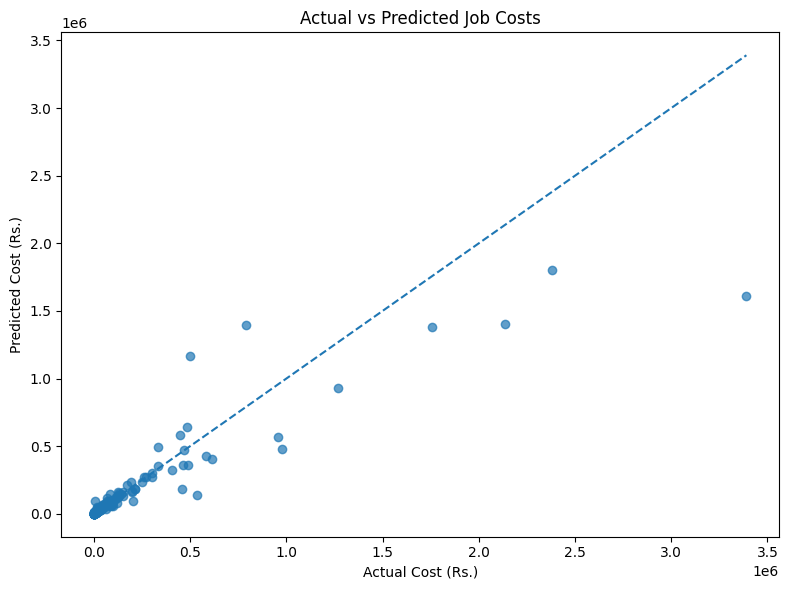

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    test_predictions,
    alpha=0.7
)

# Perfect prediction line
min_value = min(y_test.min(), test_predictions.min())
max_value = max(y_test.max(), test_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Cost (Rs.)")
plt.ylabel("Predicted Cost (Rs.)")
plt.title("Actual vs Predicted Job Costs")

plt.tight_layout()
plt.show()

In [26]:
# Identify the largest prediction errors

error_analysis = X_test.copy()

error_analysis["Actual Cost"] = y_test.values
error_analysis["Predicted Cost"] = test_predictions
error_analysis["Absolute Error"] = (
    error_analysis["Actual Cost"] -
    error_analysis["Predicted Cost"]
).abs()

error_analysis["Percentage Error"] = (
    error_analysis["Absolute Error"] /
    error_analysis["Actual Cost"]
) * 100

largest_errors = error_analysis.sort_values(
    "Absolute Error",
    ascending=False
)

largest_errors[
    [
        "Product Category",
        "Product Name",
        "Quantity",
        "Material",
        "Actual Cost",
        "Predicted Cost",
        "Absolute Error",
        "Percentage Error"
    ]
].head(15)

,Product Category,Product Name,Quantity,Material,Actual Cost,Predicted Cost,Absolute Error,Percentage Error
249,Cladding,ACP Building Cladding,10,Aluminium Composite Panel,3390400,1.613422e+06,1.776978e+06,52.412041
309,Board,Foam Board Display,10,Foam Board,2134850,1.403380e+06,7.314701e+05,34.263301
921,Board,Acrylic Display Board,5,Acrylic,497250,1.169535e+06,6.722849e+05,135.200579
110,Board,Acrylic Display Board,5,Acrylic,789050,1.394760e+06,6.057096e+05,76.764411
482,Board,PVC Display Board,10,PVC Foam Board,2380550,1.804710e+06,5.758396e+05,24.189349
305,Board,Foam Board Display,10,Foam Board,978450,4.775718e+05,5.008782e+05,51.190990
314,Calendar,Wall Calendar A3,1000,Art Paper,534450,1.426838e+05,3.917662e+05,73.302688
848,Board,Sunboard Display,10,Sunboard,955150,5.693488e+05,3.858012e+05,40.391684
594,Board,PVC Display Board,10,PVC Foam Board,1757900,1.378854e+06,3.790455e+05,21.562404
120,Flag,Satin Flag with Pole,5,Satin,1268700,9.298765e+05,3.388235e+05,26.706353


In [27]:
# Compare Random Forest configurations

from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np
import pandas as pd

configs = [
    {
        "name": "Current Model",
        "n_estimators": 300,
        "max_depth": None,
        "min_samples_split": 2,
        "min_samples_leaf": 1
    },
    {
        "name": "Tuned 1",
        "n_estimators": 500,
        "max_depth": 20,
        "min_samples_split": 2,
        "min_samples_leaf": 1
    },
    {
        "name": "Tuned 2",
        "n_estimators": 500,
        "max_depth": 25,
        "min_samples_split": 2,
        "min_samples_leaf": 1
    },
    {
        "name": "Tuned 3",
        "n_estimators": 500,
        "max_depth": None,
        "min_samples_split": 5,
        "min_samples_leaf": 2
    },
    {
        "name": "Tuned 4",
        "n_estimators": 500,
        "max_depth": 30,
        "min_samples_split": 5,
        "min_samples_leaf": 2
    }
]

tuning_results = []

for config in configs:

    model = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            (
                "model",
                RandomForestRegressor(
                    n_estimators=config["n_estimators"],
                    max_depth=config["max_depth"],
                    min_samples_split=config["min_samples_split"],
                    min_samples_leaf=config["min_samples_leaf"],
                    random_state=42,
                    n_jobs=-1
                )
            )
        ]
    )

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)

    absolute_errors = np.abs(y_test - predictions)

    wape = (
        absolute_errors.sum() /
        y_test.sum()
    ) * 100

    tuning_results.append({
        "Model": config["name"],
        "MAE": mae,
        "RMSE": rmse,
        "R²": r2,
        "WAPE": wape
    })

results_df = pd.DataFrame(tuning_results)

results_df = results_df.sort_values(
    "R²",
    ascending=False
)

results_df

,Model,MAE,RMSE,R²,WAPE
1,Tuned 1,46848.671739,171712.020141,0.795197,32.942817
0,Current Model,46307.211814,172040.808416,0.794412,32.562076
2,Tuned 2,46834.005183,172384.836461,0.793589,32.932504
3,Tuned 3,48054.591344,175945.707492,0.784973,33.790790
4,Tuned 4,48054.591344,175945.707492,0.784973,33.790790


In [28]:
# ============================================================
# ADVANCED MODEL COMPARISON AND OPTIMISATION
# ============================================================

from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor
)
from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Evaluation function
# ------------------------------------------------------------

def evaluate_model(name, model):
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    # WAPE
    wape = (
        np.sum(np.abs(y_test - predictions)) /
        np.sum(np.abs(y_test))
    ) * 100

    return {
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "WAPE": wape
    }, model


# ------------------------------------------------------------
# Models to test
# ------------------------------------------------------------

models = {

    "RF_Current": Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=300,
            random_state=42,
            max_depth=None,
            min_samples_split=2,
            min_samples_leaf=1
        ))
    ]),

    "RF_Tuned_1": Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=500,
            random_state=42,
            max_depth=None,
            min_samples_split=2,
            min_samples_leaf=1,
            max_features=0.8
        ))
    ]),

    "RF_Tuned_2": Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=500,
            random_state=42,
            max_depth=25,
            min_samples_split=2,
            min_samples_leaf=1,
            max_features="sqrt"
        ))
    ]),

    "RF_Tuned_3": Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=500,
            random_state=42,
            max_depth=30,
            min_samples_split=2,
            min_samples_leaf=2,
            max_features=0.8
        ))
    ]),

    "Extra_Trees": Pipeline([
        ("preprocessor", preprocessor),
        ("model", ExtraTreesRegressor(
            n_estimators=500,
            random_state=42,
            max_depth=None,
            min_samples_split=2,
            min_samples_leaf=1,
            max_features=1.0
        ))
    ]),

    "Gradient_Boosting": Pipeline([
        ("preprocessor", preprocessor),
        ("model", GradientBoostingRegressor(
            n_estimators=300,
            learning_rate=0.05,
            max_depth=3,
            min_samples_split=2,
            min_samples_leaf=2,
            loss="huber",
            random_state=42
        ))
    ])
}


# ------------------------------------------------------------
# Train and evaluate all models
# ------------------------------------------------------------

results = []
trained_models = {}

for name, model in models.items():

    print(f"Training {name}...")

    result, trained_model = evaluate_model(name, model)

    results.append(result)
    trained_models[name] = trained_model


# ------------------------------------------------------------
# Results table
# ------------------------------------------------------------

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="R2",
    ascending=False
).reset_index(drop=True)

print("\nMODEL COMPARISON")
print("=" * 80)

display(
    results_df.style.format({
        "MAE": "Rs. {:,.2f}",
        "RMSE": "Rs. {:,.2f}",
        "R2": "{:.4f}",
        "WAPE": "{:.2f}%"
    })
)

Training RF_Current...
Training RF_Tuned_1...
Training RF_Tuned_2...
Training RF_Tuned_3...
Training Extra_Trees...
Training Gradient_Boosting...

MODEL COMPARISON


,Model,MAE,RMSE,R2,WAPE
0,Extra_Trees,"Rs. 29,868.59","Rs. 128,679.34",0.8850,21.00%
1,RF_Tuned_1,"Rs. 45,881.26","Rs. 168,293.15",0.8033,32.26%
2,RF_Tuned_3,"Rs. 45,834.21","Rs. 169,994.44",0.7993,32.23%
3,RF_Current,"Rs. 46,307.21","Rs. 172,040.81",0.7944,32.56%
4,RF_Tuned_2,"Rs. 71,968.94","Rs. 231,374.57",0.6282,50.61%
5,Gradient_Boosting,"Rs. 62,654.77","Rs. 268,138.04",0.5006,44.06%


In [29]:
# ============================================================
# ADVANCED RANDOM FOREST OPTIMISATION
# ============================================================

from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np
import pandas as pd

rf_configs = {
    "RF_1": {
        "n_estimators": 700,
        "max_depth": None,
        "min_samples_split": 2,
        "min_samples_leaf": 1,
        "max_features": 1.0
    },

    "RF_2": {
        "n_estimators": 700,
        "max_depth": None,
        "min_samples_split": 2,
        "min_samples_leaf": 1,
        "max_features": 0.8
    },

    "RF_3": {
        "n_estimators": 700,
        "max_depth": 35,
        "min_samples_split": 2,
        "min_samples_leaf": 1,
        "max_features": 0.8
    },

    "RF_4": {
        "n_estimators": 700,
        "max_depth": 30,
        "min_samples_split": 2,
        "min_samples_leaf": 2,
        "max_features": 0.8
    },

    "RF_5": {
        "n_estimators": 700,
        "max_depth": None,
        "min_samples_split": 2,
        "min_samples_leaf": 2,
        "max_features": 1.0
    },

    "RF_6": {
        "n_estimators": 1000,
        "max_depth": None,
        "min_samples_split": 2,
        "min_samples_leaf": 1,
        "max_features": 0.8
    }
}

rf_results = []
rf_models = {}

for name, params in rf_configs.items():

    print(f"Training {name}...")

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            **params,
            random_state=42,
            n_jobs=-1
        ))
    ])

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    wape = (
        np.sum(np.abs(y_test - predictions)) /
        np.sum(np.abs(y_test))
    ) * 100

    rf_results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "WAPE": wape
    })

    rf_models[name] = model


rf_results_df = pd.DataFrame(rf_results)

rf_results_df = rf_results_df.sort_values(
    by="R2",
    ascending=False
).reset_index(drop=True)

print("\nRANDOM FOREST OPTIMISATION RESULTS")
print("=" * 70)

display(
    rf_results_df.style.format({
        "MAE": "Rs. {:,.2f}",
        "RMSE": "Rs. {:,.2f}",
        "R2": "{:.4f}",
        "WAPE": "{:.2f}%"
    })
)

Training RF_1...
Training RF_2...
Training RF_3...
Training RF_4...
Training RF_5...
Training RF_6...

RANDOM FOREST OPTIMISATION RESULTS


,Model,MAE,RMSE,R2,WAPE
0,RF_6,"Rs. 45,390.12","Rs. 166,845.67",0.8066,31.92%
1,RF_2,"Rs. 45,623.18","Rs. 167,981.95",0.8040,32.08%
2,RF_3,"Rs. 45,623.18","Rs. 167,981.95",0.8040,32.08%
3,RF_4,"Rs. 45,911.95","Rs. 170,305.44",0.7985,32.28%
4,RF_1,"Rs. 46,903.86","Rs. 173,835.92",0.7901,32.98%
5,RF_5,"Rs. 47,093.24","Rs. 173,838.55",0.7901,33.11%


In [30]:
# ============================================================
# RANDOM FOREST WITH LOG-TRANSFORMED TARGET
# ============================================================

from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import FunctionTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

log_rf = Pipeline([
    ("preprocessor", preprocessor),
    ("model", TransformedTargetRegressor(
        regressor=RandomForestRegressor(
            n_estimators=700,
            max_depth=None,
            min_samples_split=2,
            min_samples_leaf=1,
            max_features=0.8,
            random_state=42,
            n_jobs=-1
        ),
        func=np.log1p,
        inverse_func=np.expm1
    ))
])

# Train
log_rf.fit(X_train, y_train)

# Predict
log_rf_predictions = log_rf.predict(X_test)

# Evaluation
log_rf_mae = mean_absolute_error(y_test, log_rf_predictions)
log_rf_rmse = np.sqrt(
    mean_squared_error(y_test, log_rf_predictions)
)
log_rf_r2 = r2_score(y_test, log_rf_predictions)

log_rf_wape = (
    np.sum(np.abs(y_test - log_rf_predictions)) /
    np.sum(np.abs(y_test))
) * 100

print("RANDOM FOREST - LOG TARGET")
print("=" * 40)
print(f"MAE:  Rs. {log_rf_mae:,.2f}")
print(f"RMSE: Rs. {log_rf_rmse:,.2f}")
print(f"R²:   {log_rf_r2:.4f}")
print(f"WAPE: {log_rf_wape:.2f}%")

RANDOM FOREST - LOG TARGET
MAE:  Rs. 35,899.89
RMSE: Rs. 141,571.68
R²:   0.8608
WAPE: 25.24%


In [31]:
# ============================================================
# RANDOM FOREST - DIFFERENT CRITERIA
# ============================================================

criteria = ["squared_error", "absolute_error", "poisson"]

criterion_results = []
criterion_models = {}

for criterion in criteria:

    print(f"Training RF with criterion: {criterion}...")

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=700,
            max_depth=None,
            min_samples_split=2,
            min_samples_leaf=1,
            max_features=0.8,
            criterion=criterion,
            random_state=42,
            n_jobs=-1
        ))
    ])

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    wape = (
        np.sum(np.abs(y_test - predictions)) /
        np.sum(np.abs(y_test))
    ) * 100

    criterion_results.append({
        "Criterion": criterion,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "WAPE": wape
    })

    criterion_models[criterion] = model

criterion_results_df = pd.DataFrame(criterion_results)

criterion_results_df = criterion_results_df.sort_values(
    by="R2",
    ascending=False
).reset_index(drop=True)

print("\nRANDOM FOREST CRITERION COMPARISON")
print("=" * 70)

display(
    criterion_results_df.style.format({
        "MAE": "Rs. {:,.2f}",
        "RMSE": "Rs. {:,.2f}",
        "R2": "{:.4f}",
        "WAPE": "{:.2f}%"
    })
)

Training RF with criterion: squared_error...
Training RF with criterion: absolute_error...
Training RF with criterion: poisson...

RANDOM FOREST CRITERION COMPARISON


,Criterion,MAE,RMSE,R2,WAPE
0,absolute_error,"Rs. 31,878.84","Rs. 127,906.74",0.8864,22.42%
1,poisson,"Rs. 36,002.72","Rs. 136,143.50",0.8713,25.32%
2,squared_error,"Rs. 45,623.18","Rs. 167,981.95",0.8040,32.08%


In [32]:
# ============================================================
# BEST RANDOM FOREST - 5-FOLD CROSS-VALIDATION
# ============================================================

best_rf = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=700,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        max_features=0.8,
        criterion="absolute_error",
        random_state=42,
        n_jobs=-1
    ))
])

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

best_rf_cv_scores = cross_val_score(
    best_rf,
    X,
    y,
    cv=cv,
    scoring="r2"
)

print("BEST RANDOM FOREST - 5-FOLD CROSS-VALIDATION")
print("=" * 50)
print("Fold R² scores:", best_rf_cv_scores)
print(f"Mean R²: {best_rf_cv_scores.mean():.4f}")
print(f"Std R²: {best_rf_cv_scores.std():.4f}")

BEST RANDOM FOREST - 5-FOLD CROSS-VALIDATION
Fold R² scores: [0.88890555 0.92004881 0.92209367 0.94902176 0.9481119 ]
Mean R²: 0.9256
Std R²: 0.0221


In [38]:
# Final evaluation of the optimized Random Forest model

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Fit the selected Random Forest on the training data
best_rf.fit(X_train, y_train)

# Predict on the untouched test set
best_rf_predictions = best_rf.predict(X_test)

# Evaluation metrics
final_mae = mean_absolute_error(y_test, best_rf_predictions)
final_rmse = np.sqrt(mean_squared_error(y_test, best_rf_predictions))
final_r2 = r2_score(y_test, best_rf_predictions)

# WAPE
final_wape = (
    np.sum(np.abs(y_test - best_rf_predictions)) /
    np.sum(np.abs(y_test))
) * 100

# MAPE
final_mape = (
    np.mean(np.abs((y_test - best_rf_predictions) / y_test))
) * 100

# Approximate accuracy
final_accuracy = 100 - final_mape

print("FINAL OPTIMIZED RANDOM FOREST - TEST SET")
print("=" * 50)
print(f"MAE:       Rs. {final_mae:,.2f}")
print(f"RMSE:      Rs. {final_rmse:,.2f}")
print(f"R²:        {final_r2:.4f}")
print(f"WAPE:      {final_wape:.2f}%")
print(f"MAPE:      {final_mape:.2f}%")
print(f"Accuracy:  {final_accuracy:.2f}%")

FINAL OPTIMIZED RANDOM FOREST - TEST SET
MAE:       Rs. 31,878.84
RMSE:      Rs. 127,906.74
R²:        0.8864
WAPE:      22.42%
MAPE:      28.07%
Accuracy:  71.93%
